In [110]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics # 분류와 숫자 예측에 사용하는 모델 모음,모델의 예측 성능을 평가하는 도구 모음
from sklearn.neighbors import KNeighborsClassifier  #분류(가까운 이웃 데이터를 참고해 종류를 분류)
from sklearn.neighbors import KNeighborsRegressor   #예측(가까운 이웃데이터를 참고해 숫자를 예측)

from sklearn.preprocessing import PolynomialFeatures # 다항특성 (x², x₁ × x₂ 같은 특성을 추가)
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩(문자형 번주를 0과1로 변환)

from sklearn.linear_model import LinearRegression   #예측 (입력과 결과의 선형관례를 학습해 숫자를 예측)
from sklearn.linear_model import Ridge              #릿지 (계수가 지나치게 커지는 것을 억제하는 선형 회귀)
from sklearn.linear_model import Lasso              #라쏘 (일부 계수를 0으로 만들어 특성 선택에도 활용하는 선형 회귀)
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위 (실제값과 예측값의 차이를 절댓값으로 구한 뒤 평균 계산)
from sklearn.preprocessing import StandardScaler # 표준화 (각 특성을 평균 0, 표준편차 1 기준으로 표준화)
from sklearn.model_selection import train_test_split #(데이터를 학습용과 평가용으로 분리)
from scipy.special import expit

In [111]:
# [ 도미 ]-35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ]-14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

1. 도미와 빙어 구분하는 머신러닝을 구성하시오
-길이 21 무게90 의 고기를 예측하시오(로지스틱 알고리즘을 사용)
2. 도미 빙어 길이와 무게의 산점도 그래프를 출력하시오
3. 길이 25, 무게 150의 생선을 예측하시오.

In [112]:
len(bream_length)
len(smelt_length)

14

In [113]:
# 데이터 전처리
# 도미, 빙어 데이터 합치기
length= bream_length+smelt_length
weight= bream_weight+smelt_weight

data= np.column_stack((length,weight))
label= ['bream']*35+['smelt']*14

In [114]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [115]:
# 정규화
ss=StandardScaler()
ss.fit(train_data)

train_scaled= ss.transform(train_data)
test_scaled= ss.transform(test_data)

In [116]:
# 로지스틱
# 학습
lr=LogisticRegression()
lr.fit(train_scaled, train_label)

# 예상
result=lr.predict(test_scaled)
print("예상:", result)

# 정확도
print("train정확도:",lr.score(train_scaled, train_label))
print("test정확도:",lr.score(test_scaled, test_label))

예상: ['bream' 'smelt' 'smelt' 'smelt' 'bream' 'bream' 'bream' 'bream' 'bream'
 'bream' 'bream' 'bream' 'bream']
train정확도: 1.0
test정확도: 1.0


In [117]:
lr.predict_proba(test_scaled[:5])

array([[0.94088243, 0.05911757],
       [0.11387061, 0.88612939],
       [0.15599382, 0.84400618],
       [0.10985197, 0.89014803],
       [0.98807467, 0.01192533]])

In [118]:
decisions= lr.decision_function(test_scaled[:5])
np.round(decisions, decimals=4)
expit(decisions)


array([0.05911757, 0.88612939, 0.84400618, 0.89014803, 0.01192533])

In [119]:
# in_data = input('생선의 길이,무게를 입력하세요.>> 예)21,90 ')
in_data = '21,9'
in_data = in_data.split(',')
in_data2 = list(map(float,in_data))
in_data2

[21.0, 9.0]

In [122]:
new=[[21,90]]
new2=[[25,150]]

# 정규화
ss=StandardScaler()
ss.fit(train_data)

new_scaled= ss.transform(new)
new2_scaled= ss.transform(new2)

# 길이 21 무게90 의 고기를 예측하시오(로지스틱 알고리즘을 사용)
result2=lr.predict(new_scaled)
proba2=lr.predict_proba(new_scaled)
print(f"생선종류:{result2[0]}({proba2[0][1]*100:.2f}%)")

# 길이 25, 무게 150의 생선을 예측하시오.
result3=lr.predict(new2_scaled)
proba3=lr.predict_proba(new2_scaled)
print(f"생선종류:{result3[0]}({proba3[0][0]*100:.2f}%)")

생선종류:smelt(55.23%)
생선종류:bream(67.84%)


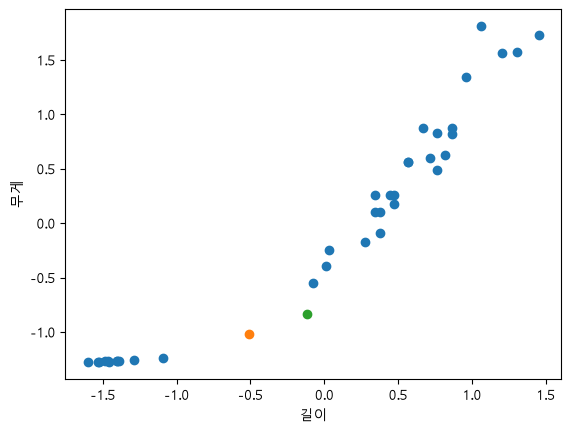

In [121]:
# train_scaled[:,0]: 길이, train_scaled[:,1]: 무게
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1])
plt.scatter(new2_scaled[:,0],new2_scaled[:,1])

plt.xlabel('길이')
plt.ylabel('무게')
plt.show()